[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/06-nlp-and-transformers/notebooks/02-attention-by-hand.ipynb)

# 02 - Attention by hand (NumPy)

**Goal:** compute **self-attention** — the core calculation inside every transformer — for the 3-word sentence "the cat sat", using only NumPy (Python's library for arrays of numbers). Then compare it with the real attention weights of a small pretrained model.

No downloads in sections 1-6. Section 7 downloads DistilBERT (about 270 MB).

## 1. Embeddings for three words

Each word gets a vector of 4 numbers. These are hand-made so we can follow the maths; in a real model they are learned. One row = one word.

In [1]:
import numpy as np
np.set_printoptions(precision=3, suppress=True)

words = ["the", "cat", "sat"]
X = np.array([
    [1.0, 0.0, 0.0, 0.2],   # the
    [0.0, 1.0, 0.8, 0.0],   # cat
    [0.0, 0.6, 1.0, 1.0],   # sat
])
print("X shape:", X.shape, "(3 words, 4 numbers each)")

X shape: (3, 4) (3 words, 4 numbers each)


## 2. Query, Key and Value matrices

Three **weight matrices** turn each embedding into:
- a **query** (what this word is looking for),
- a **key** (the label it offers to others),
- a **value** (the information it hands over).

Each matrix is 4×3: 4 numbers in, 3 out. `@` is NumPy's matrix-multiply operator.

In [2]:
W_q = np.array([[0.5, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.5, 1.0], [0.0, 1.0, 0.5]])
W_k = np.array([[0.3, 0.0, 0.0], [0.0, 1.0, 0.5], [0.0, 0.5, 0.5], [0.2, 0.0, 0.0]])
W_v = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [0.0, 0.5, 0.5]])

Q, K, V = X @ W_q, X @ W_k, X @ W_v
print("Q =\n", Q, "\nK =\n", K, "\nV =\n", V)

Q =
 [[0.5 0.2 0.1]
 [0.  1.4 0.8]
 [0.  2.1 1.5]] 
K =
 [[0.34 0.   0.  ]
 [0.   1.4  0.9 ]
 [0.2  1.1  0.8 ]] 
V =
 [[1.  0.1 0.1]
 [0.  1.  0.8]
 [0.  1.1 1.5]]


## 3. Step 1 and 2: scores, then scale

Every query is compared with every key using a **dot product** (multiply matching numbers and add). `K.T` is K **transposed** (rows become columns) so that one matrix multiply compares all pairs at once. We divide by √d (d = 3) to keep the numbers moderate.

In [3]:
d = Q.shape[1]
scores = Q @ K.T / np.sqrt(d)
print("Scaled scores (row = word asking, column = word being looked at):\n", scores)

# Check one cell by hand: 'sat' (row 2) looking at 'cat' (column 1)
manual = sum(Q[2, i] * K[1, i] for i in range(d)) / np.sqrt(d)
print("sat->cat by hand:", round(manual, 3), " from matrix:", round(scores[2, 1], 3))

Scaled scores (row = word asking, column = word being looked at):
 [[0.098 0.214 0.231]
 [0.    1.547 1.259]
 [0.    2.477 2.026]]
sat->cat by hand: 2.477  from matrix: 2.477


## 4. Step 3: softmax

**Softmax** turns a row of scores into positive weights that add up to 1: take e (≈2.718) to the power of each score, then divide by the row total. Bigger score → bigger share.

In [4]:
def softmax(s):
    e = np.exp(s - s.max(axis=-1, keepdims=True))   # subtracting the max avoids huge numbers; result is identical
    return e / e.sum(axis=-1, keepdims=True)

weights = softmax(scores)
print("Attention weights:\n", weights)
print("Row sums:", weights.sum(axis=1))

Attention weights:
 [[0.306 0.344 0.35 ]
 [0.108 0.51  0.382]
 [0.049 0.581 0.37 ]]
Row sums: [1. 1. 1.]


## 5. Step 4: blend the values
Each word's new vector is the weighted average of all value vectors. 'sat' now carries a lot of 'cat' information — it knows who is sitting.

In [5]:
output = weights @ V
for w, row in zip(words, output):
    print(f"{w:>4} ->", row)

 the -> [0.306 0.759 0.83 ]
 cat -> [0.108 0.941 0.991]
 sat -> [0.049 0.993 1.025]


## 6. Heatmap, and the causal mask
A **causal mask** stops each word from looking at words to its right, which is what text-generating models do (they must not see the future). We set those scores to minus infinity, so softmax gives them weight 0.

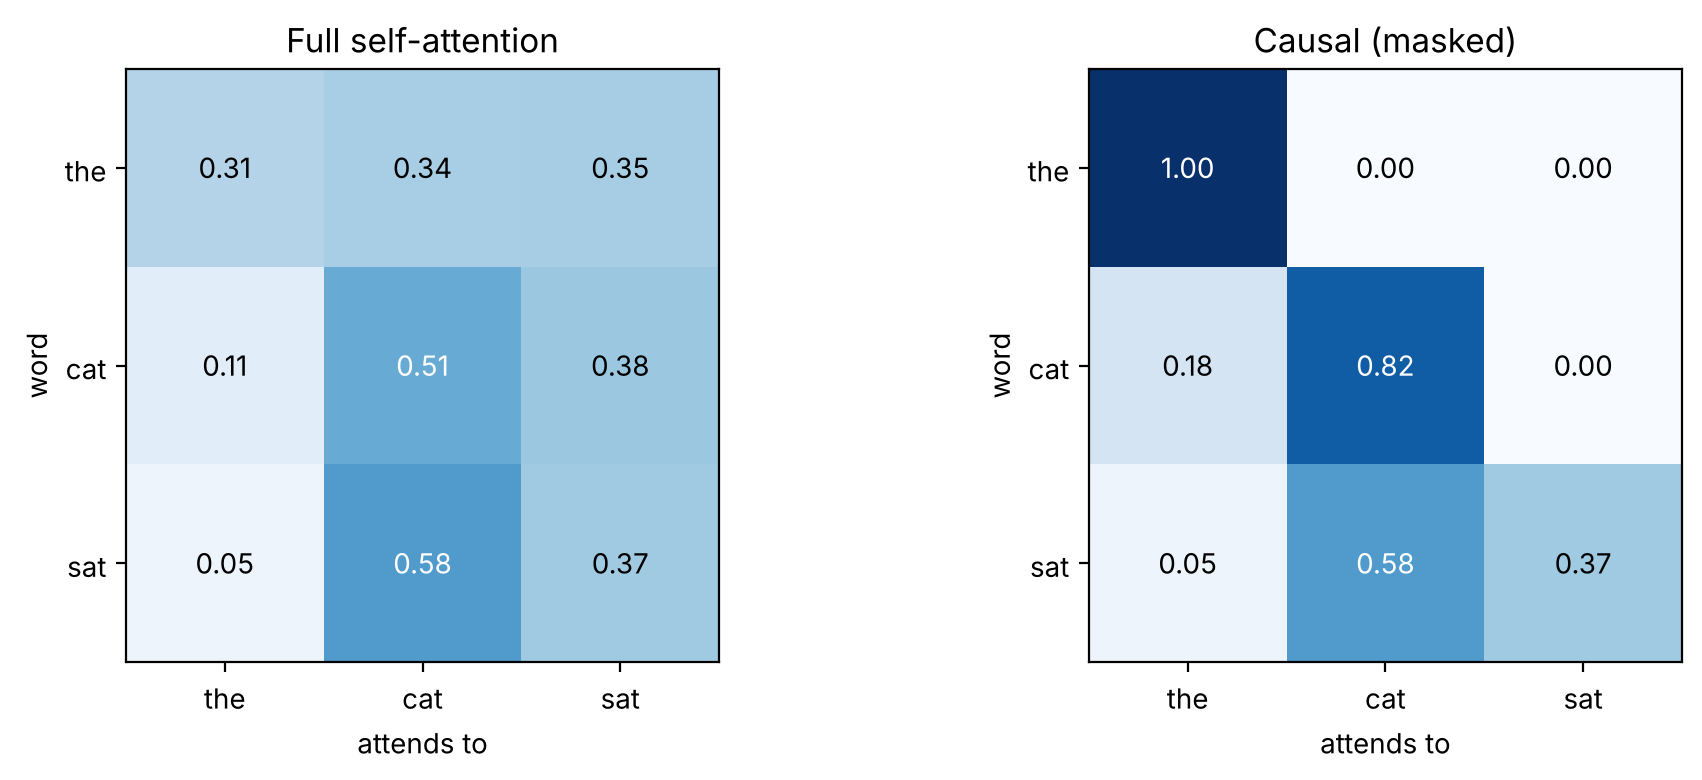

In [6]:
import matplotlib.pyplot as plt

mask = np.triu(np.ones((3, 3)), k=1).astype(bool)        # True above the diagonal = "future"
causal_weights = softmax(np.where(mask, -np.inf, scores))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, w, title in [(axes[0], weights, "Full self-attention"), (axes[1], causal_weights, "Causal (masked)")]:
    ax.imshow(w, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(3), labels=words); ax.set_yticks(range(3), labels=words)
    ax.set_xlabel("attends to"); ax.set_ylabel("word")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{w[i, j]:.2f}", ha="center", va="center", color="white" if w[i, j] > 0.5 else "black")
    ax.set_title(title)
plt.tight_layout(); plt.show()

## 7. Multi-head attention in a few lines

**Multi-head attention** runs several attention calculations with different matrices, then joins (concatenates) the results. Here we make 2 random heads to show the shapes.

In [7]:
rng = np.random.default_rng(0)

def one_head(X, d_head=2):
    Wq, Wk, Wv = (rng.normal(size=(X.shape[1], d_head)) for _ in range(3))
    q, k, v = X @ Wq, X @ Wk, X @ Wv
    return softmax(q @ k.T / np.sqrt(d_head)) @ v

heads = [one_head(X) for _ in range(2)]
combined = np.concatenate(heads, axis=1)
print("each head output:", heads[0].shape, " combined:", combined.shape)

each head output: (3, 2)  combined: (3, 4)


## 8. Real attention from a pretrained model

Now look at a trained model. `output_attentions=True` asks DistilBERT to return its attention weights: one grid per layer per head. DistilBERT has 6 layers × 12 heads. The tokenizer adds special tokens `[CLS]` (start) and `[SEP]` (end).

In [8]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

name = "distilbert-base-uncased-finetuned-sst-2-english"
tok = AutoTokenizer.from_pretrained(name)
# attn_implementation="eager" = plain maths, so the attention weights can be returned
model = AutoModelForSequenceClassification.from_pretrained(name, attn_implementation="eager")
inputs = tok("the animal didn't cross the street because it was tired", return_tensors="pt")
with torch.no_grad():
    out = model(**inputs, output_attentions=True)
tokens = tok.convert_ids_to_tokens(inputs["input_ids"][0])
print("tokens:", tokens)
print("layers:", len(out.attentions), " shape of one layer:", tuple(out.attentions[0].shape), "(batch, heads, tokens, tokens)")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 3238.65it/s]

tokens: ['[CLS]', 'the', 'animal', 'didn', "'", 't', 'cross', 'the', 'street', 'because', 'it', 'was', 'tired', '[SEP]']
layers: 6  shape of one layer: (1, 12, 14, 14) (batch, heads, tokens, tokens)


Real heads are messy: many look at nearby words, punctuation or `[SEP]`. Let's search all 6 × 12 = 72 heads for the one where `it` pays the most attention to `animal`, and compare with `street`.

In [9]:
i, a, s = tokens.index("it"), tokens.index("animal"), tokens.index("street")
best = max(((l, h) for l in range(6) for h in range(12)),
           key=lambda lh: float(out.attentions[lh[0]][0, lh[1], i, a]))
layer, head = best
att = out.attentions[layer][0, head].numpy()
print(f"Best head: layer {layer}, head {head}")
print(f"  it -> animal: {att[i, a]:.2f}    it -> street: {att[i, s]:.3f}")

Best head: layer 4, head 0
  it -> animal: 0.79    it -> street: 0.003


Plot that head. Read the row for `it`: one dark square over `animal`. This head seems to have learned something like 'link a pronoun to the noun it refers to' — nobody programmed that; it emerged from training.

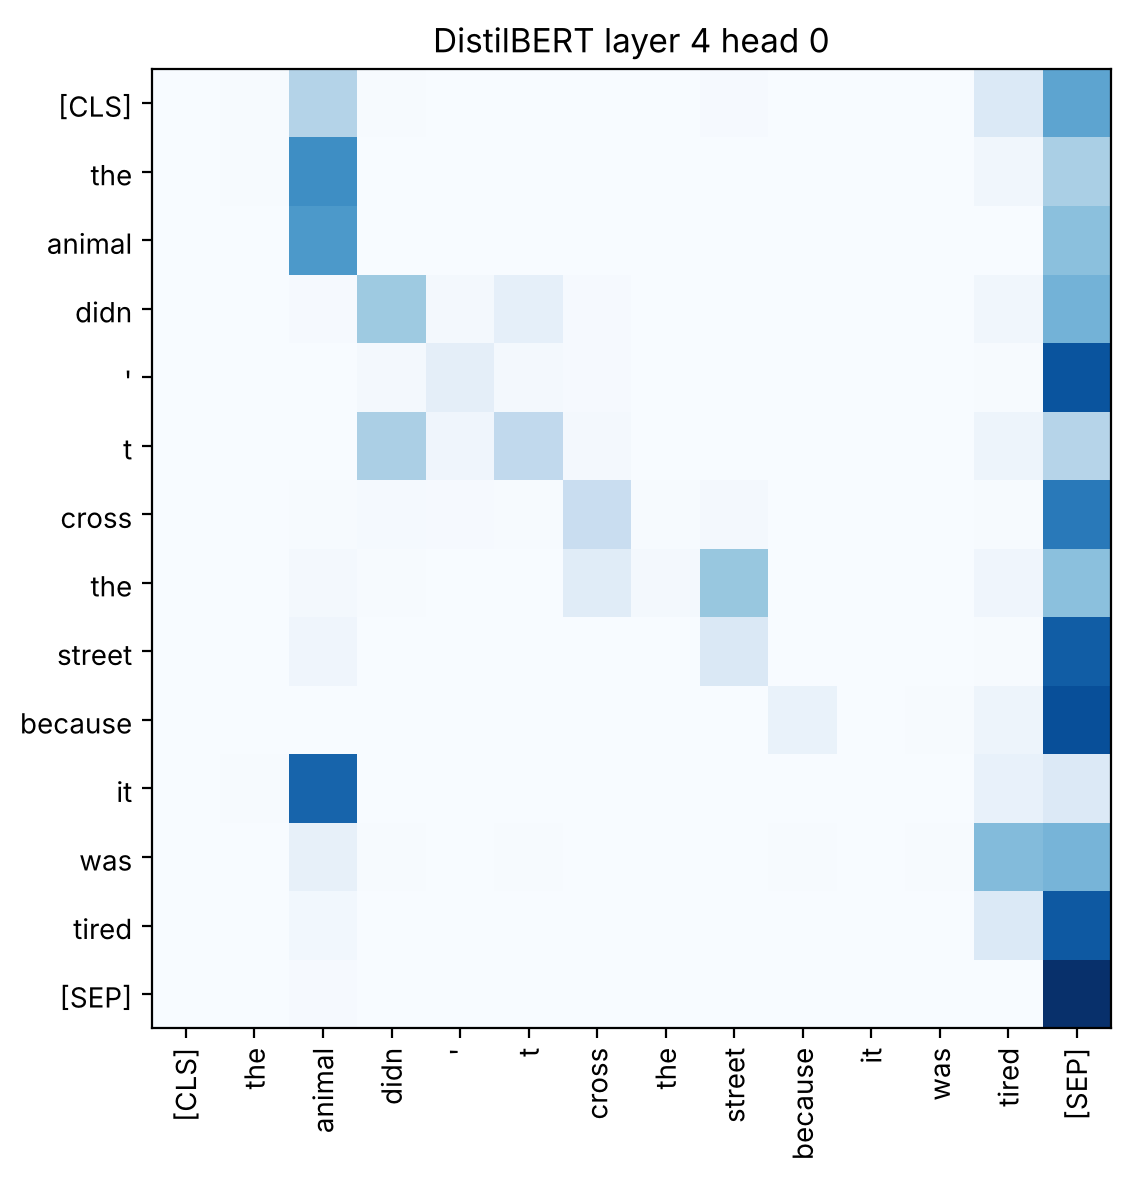

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(att, cmap="Blues")
ax.set_xticks(range(len(tokens)), labels=tokens, rotation=90)
ax.set_yticks(range(len(tokens)), labels=tokens)
ax.set_title(f"DistilBERT layer {layer} head {head}")
plt.tight_layout(); plt.show()

## Try it yourself
1. Change the embedding of "sat" so it attends more to "the". Which numbers did you change?
2. Remove the `/ np.sqrt(d)` scaling and multiply X by 10. What happens to the weights? (They become almost all-or-nothing.)
3. For every head in layer 0, print which token `it` attends to most. Are early layers more "local" (looking at neighbours)?